In [3]:
%pip install pdf2image

Note: you may need to restart the kernel to use updated packages.


'DOSKEY' ���O�����Υ~���R�O�B�i���檺�{���Χ妸�ɡC


In [4]:
%pip install pymupdf opencv-python numpy matplotlib

   ---------------------------------------- 0.0/19.8 MB ? eta -:--:--
    --------------------------------------- 0.3/19.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/19.8 MB 2.8 MB/s eta 0:00:07
   -- ------------------------------------- 1.0/19.8 MB 2.2 MB/s eta 0:00:09
   --- ------------------------------------ 1.6/19.8 MB 2.4 MB/s eta 0:00:08
   ---- ----------------------------------- 2.1/19.8 MB 2.4 MB/s eta 0:00:08
   ----- ---------------------------------- 2.6/19.8 MB 2.4 MB/s eta 0:00:08
   ------ --------------------------------- 3.1/19.8 MB 2.4 MB/s eta 0:00:08
   ------- -------------------------------- 3.7/19.8 MB 2.4 MB/s eta 0:00:07
   -------- ------------------------------- 4.2/19.8 MB 2.4 MB/s eta 0:00:07
   --------- ------------------------------ 4.7/19.8 MB 2.4 MB/s eta 0:00:07
   ---------- ----------------------------- 5.2/19.8 MB 2.4 MB/s eta 0:00:07
   ----------- ---------------------------- 5.8/19.8 MB 2.4 MB/s eta 0:00:06
   ----------

'DOSKEY' ���O�����Υ~���R�O�B�i���檺�{���Χ妸�ɡC
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


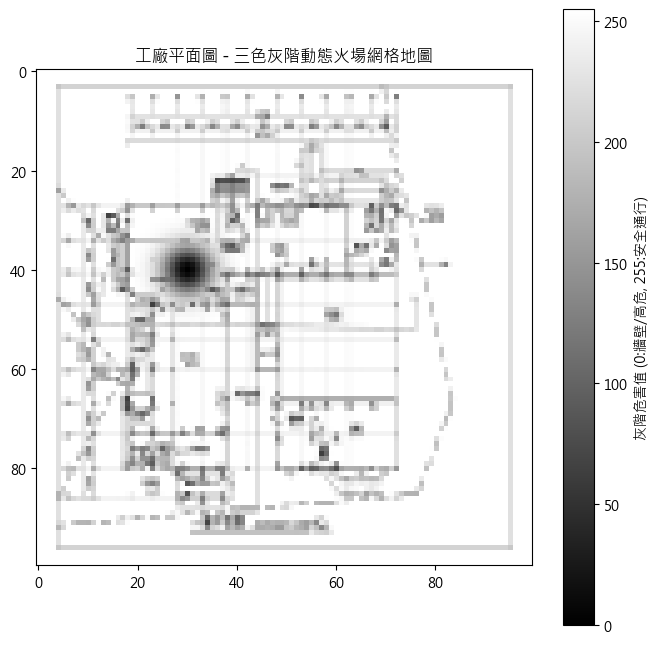

In [ ]:
import fitz  # PyMuPDF
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 直接讀取 PDF 頁面轉換為圖像矩陣 (免安裝 Poppler)
pdf_path = "工廠平面.pdf"
doc = fitz.open(pdf_path)
page = doc[0]  # 取得第一頁
# 設定渲染解析度
zoom = 300 / 72 
mat = fitz.Matrix(zoom, zoom)
pix = page.get_pixmap(matrix=mat)

# 將 PyMuPDF 圖像轉為 NumPy 灰階陣列
image = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
if pix.n == 4:  # 若含 RGBA 則轉灰階
    gray = cv2.cvtColor(image, cv2.COLOR_RGBA2GRAY)
else:
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# 2. 影像預處理：二值化提取牆體與障礙物 (牆壁轉 0，走道/空間轉 255)
_, binary_map = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)

# 3. 牆體膨脹處理 (Dilate) - 為人員/機器人預留安全碰撞半徑
kernel = np.ones((3, 3), np.uint8)
dilated_map = cv2.erode(binary_map, kernel, iterations=1)

# 4. 縮放到演算法使用的指定網格解析度 (如 100 x 100)
grid_size = (100, 100)
grid_map = cv2.resize(dilated_map, grid_size, interpolation=cv2.INTER_AREA)

# 5. 模擬泊松火源與煙霧擴散 (以加工區網格座標 (30, 40) 為例)
fire_smoke_matrix = np.zeros(grid_size, dtype=np.float32)
fire_x, fire_y = 30, 40
fire_smoke_matrix[fire_y, fire_x] = 255.0

# 高斯擴散模擬流體力學煙霧層
smoke_layer = cv2.GaussianBlur(fire_smoke_matrix, (21, 21), 0)

# 6. 標準化與反轉 (公式: New_M = 256 - M)
smoke_normalized = cv2.normalize(smoke_layer, None, 0, 255, cv2.NORM_MINMAX)
smoke_inverted = 255 - smoke_normalized

# 7. 合併靜態建築障礙物與動態煙霧層 (取最小值)
final_gray_grid = np.minimum(grid_map, smoke_inverted)

# 8. 顯示三色灰階動態火場網格地圖
plt.figure(figsize=(8, 8))
plt.imshow(final_gray_grid, cmap='gray')
plt.title("工廠平面圖 - 三色灰階動態火場網格地圖")
plt.colorbar(label="灰階危害值 (0:牆壁/高危, 255:安全通行)")
plt.show()

## 方案一：Matplotlib 互動式畫筆點擊編輯器（最方便、Python 原生）
在 Jupyter Notebook 或 Python GUI 中，直接利用 matplotlib 的滑鼠事件（button_press_event 或 motion_notify_event），讓您可以 用滑鼠點擊或拖曳 網格：滑鼠左鍵：點擊/塗抹網格，將該區塊劃記為 牆壁 (灰階值 0)。   滑鼠右鍵：清除點擊的網格，還原為 可通行區域 (灰階值 255)。   隨時匯出/更新：修改完畢後按下鍵盤按鍵（例如按 s），自動存成最新的 numpy 矩陣 .npy 或 .png 檔，供 AACO 演算法即時帶入重規劃。   

成功從 PDF 提取基礎牆體結構！


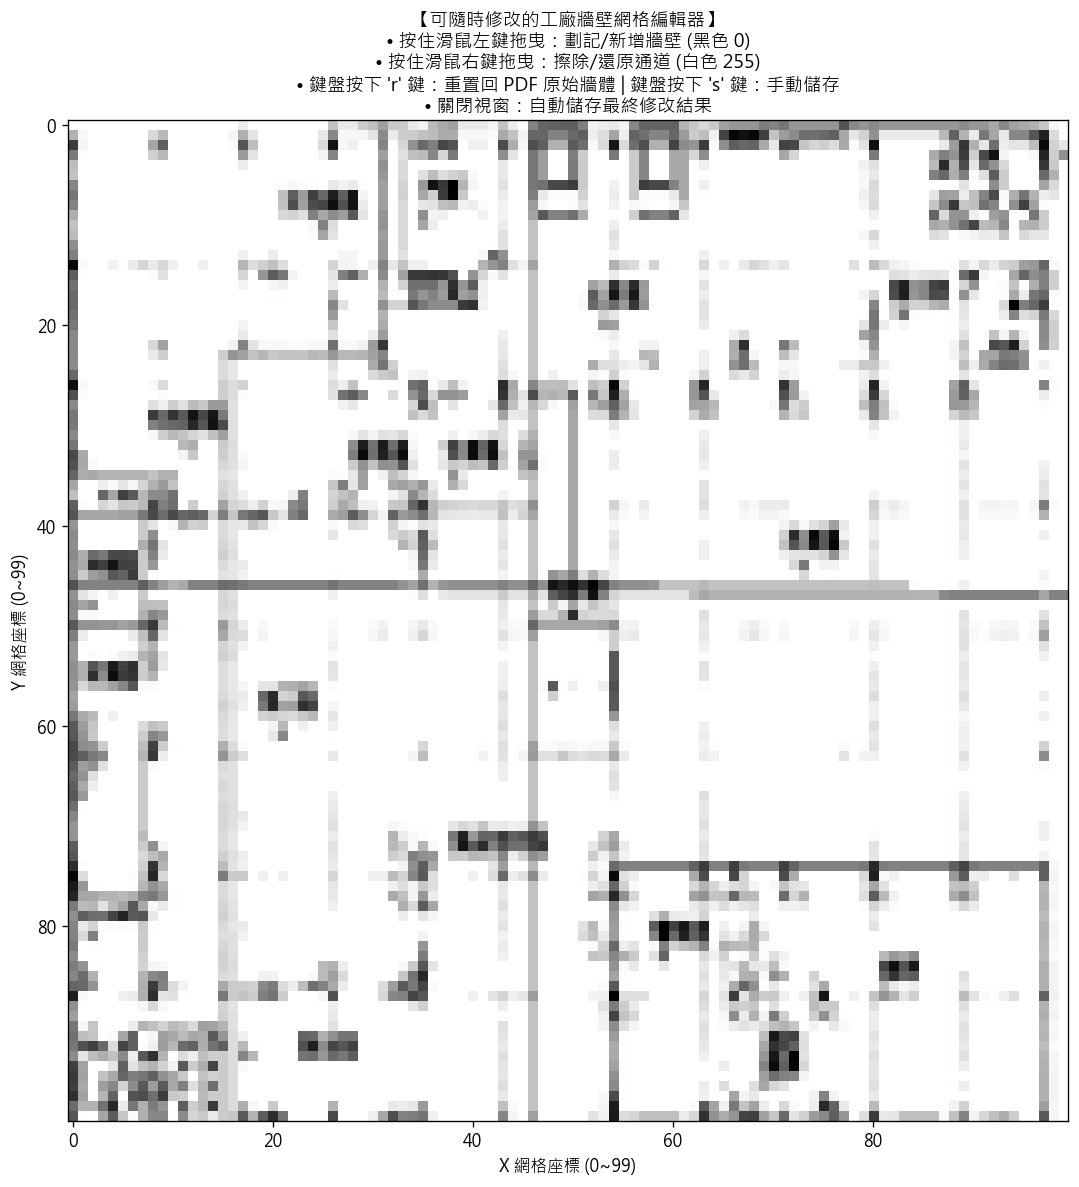

修改後的牆壁網格矩陣已成功儲存為 'custom_pdf_wall_matrix.npy' 與 'custom_pdf_wall_matrix.png'！


In [9]:
import fitz  # PyMuPDF 套件
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. 字型與顯示設定 (避免 Matplotlib 中文警告)
# ==========================================
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 1. 匯入 PDF 並自動提取二值化牆體網格
# ==========================================
pdf_path = "factory.jpg"
grid_rows, grid_cols = 100, 100  # 設定網格解析度 (如 100x100)

try:
    doc = fitz.open(pdf_path)
    page = doc[0]
    zoom = 300 / 72  # 300 DPI 高解析度渲染
    mat = fitz.Matrix(zoom, zoom)
    pix = page.get_pixmap(matrix=mat)
    
    # 轉為灰階影像
    img_np = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    if pix.n == 4:
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGBA2GRAY)
    else:
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        
    # 影像二值化提取牆體 (牆壁轉 0，走道轉 255)
    _, binary_map = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    dilated_map = cv2.erode(binary_map, kernel, iterations=1) # 牆體邊界膨脹
    
    # 縮放到指定的演算法網格尺寸
    wall_matrix = cv2.resize(dilated_map, (grid_cols, grid_rows), interpolation=cv2.INTER_AREA)
    print("成功從 PDF 提取基礎牆體結構！")
    
except Exception as e:
    print(f"匯入 PDF 失敗 ({e})，改為建立 100x100 空白地圖。")
    wall_matrix = np.full((grid_rows, grid_cols), 255, dtype=np.uint8)

# 保留一份原始提取的牆體底圖 (用於方便對照與重置)
original_wall_matrix = wall_matrix.copy()

# ==========================================
# 2. 建立【可隨時修改的牆壁網格編輯器】
# ==========================================
fig, ax = plt.subplots(figsize=(10, 10), dpi=120)
im = ax.imshow(wall_matrix, cmap='gray', vmin=0, vmax=255)

title_text = (
    "【可隨時修改的工廠牆壁網格編輯器】\n"
    "• 按住滑鼠左鍵拖曳：劃記/新增牆壁 (黑色 0)\n"
    "• 按住滑鼠右鍵拖曳：擦除/還原通道 (白色 255)\n"
    "• 鍵盤按下 'r' 鍵：重置回 PDF 原始牆體 | 鍵盤按下 's' 鍵：手動儲存\n"
    "• 關閉視窗：自動儲存最終修改結果"
)
ax.set_title(title_text, fontsize=11)
ax.set_xlabel("X 網格座標 (0~99)")
ax.set_ylabel("Y 網格座標 (0~99)")

drawing = False  # 紀錄滑鼠是否處於按下拖曳狀態
brush_size = 1   # 筆刷大小 (1 表示以點為中心 3x3 區域，可自訂)

def update_point(x, y, value):
    """更新滑鼠點擊位置對應的網格像素值"""
    col = int(x + 0.5)
    row = int(y + 0.5)
    if 0 <= col < grid_cols and 0 <= row < grid_rows:
        # 修改點擊點周圍的網格區塊 (實現塗刷效果)
        r_min = max(0, row - brush_size)
        r_max = min(grid_rows, row + brush_size + 1)
        c_min = max(0, col - brush_size)
        c_max = min(grid_cols, col + brush_size + 1)
        
        wall_matrix[r_min:r_max, c_min:c_max] = value
        im.set_data(wall_matrix)
        fig.canvas.draw_idle()

def on_button_press(event):
    global drawing
    if event.inaxes == ax:
        drawing = True
        val = 0 if event.button == 1 else 255  # 左鍵:0(新增牆壁), 右鍵:255(擦除通道)
        update_point(event.xdata, event.ydata, val)

def on_motion(event):
    if drawing and event.inaxes == ax:
        val = 0 if event.button == 1 else 255
        update_point(event.xdata, event.ydata, val)

def on_button_release(event):
    global drawing
    drawing = False

def on_key_press(event):
    global wall_matrix
    if event.key == 'r':  # 按 'r' 鍵重置
        wall_matrix[:] = original_wall_matrix.copy()
        im.set_data(wall_matrix)
        fig.canvas.draw_idle()
        print("已重置為 PDF 原始提取牆體！")
    elif event.key == 's':  # 按 's' 鍵手動儲存
        save_current_matrix()

def save_current_matrix():
    np.save("custom_pdf_wall_matrix.npy", wall_matrix)
    cv2.imwrite("custom_pdf_wall_matrix.png", wall_matrix)
    print("修改後的牆壁網格矩陣已成功儲存為 'custom_pdf_wall_matrix.npy' 與 'custom_pdf_wall_matrix.png'！")

# 綁定滑鼠與鍵盤互動事件
fig.canvas.mpl_connect('button_press_event', on_button_press)
fig.canvas.mpl_connect('motion_notify_event', on_motion)
fig.canvas.mpl_connect('button_release_event', on_button_release)
fig.canvas.mpl_connect('key_press_event', on_key_press)

plt.tight_layout()
plt.show()

# 視窗關閉時自動存檔
save_current_matrix()

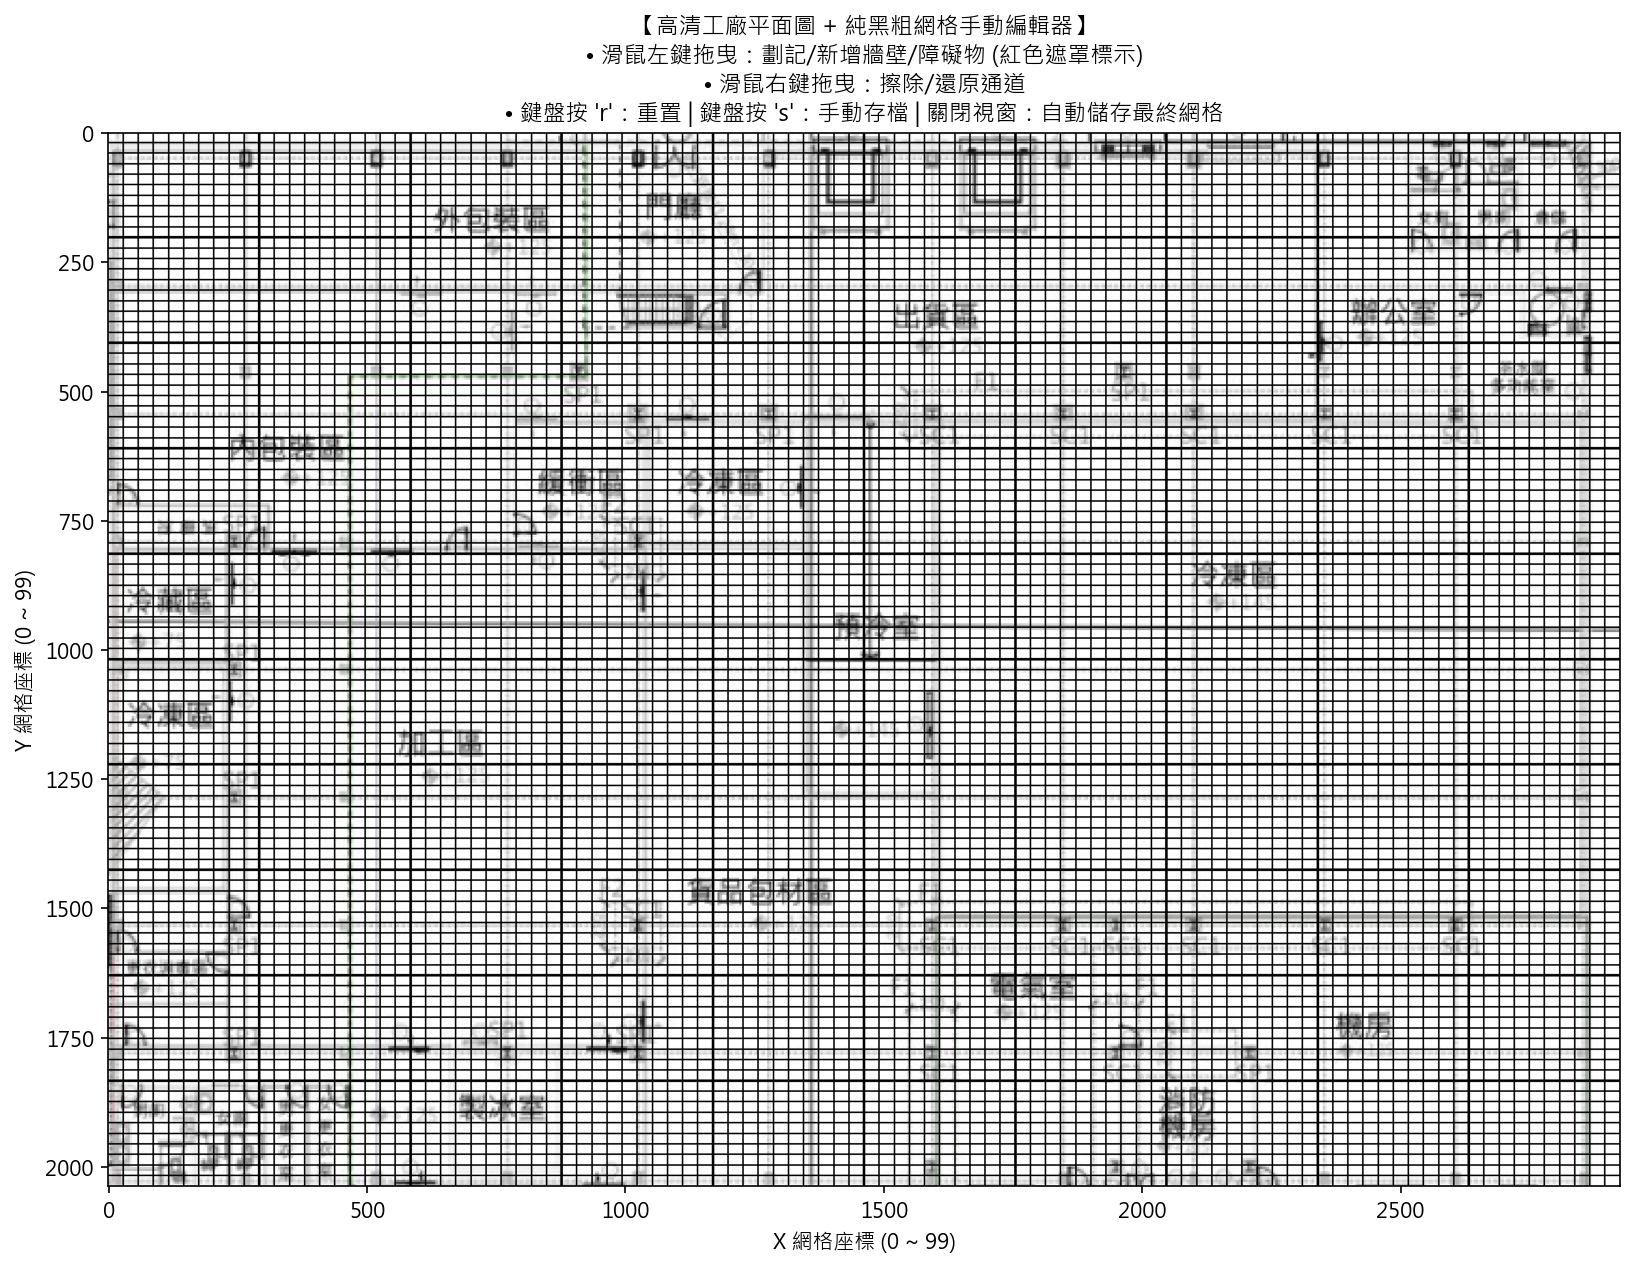

修改後的牆壁網格矩陣已成功儲存為 'custom_pdf_wall_matrix.npy' 與 'custom_pdf_wall_matrix.png'！


In [11]:
import fitz  # PyMuPDF 套件
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. 中文字型與介面顯示設定
# ==========================================
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 1. 讀取 PDF 並以 300 DPI 高解析度渲染 (保證原圖極度清晰)
# ==========================================
pdf_path = "factory.jpg"
grid_rows, grid_cols = 100, 100  # 設定網格解析度 (可改 50x50 或 100x100)

doc = fitz.open(pdf_path)
page = doc[0]

# 設定 300 DPI 高畫質放大渲染 (解決原圖模糊問題)
zoom = 300 / 72 
mat = fitz.Matrix(zoom, zoom)
pix = page.get_pixmap(matrix=mat)

# 轉為高解析度 RGB 影像與灰階影像
high_res_rgb = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
if pix.n == 4:
    high_res_rgb = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGBA2RGB)
    gray = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGB2GRAY)
else:
    gray = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGB2GRAY)

h, w, _ = high_res_rgb.shape

# ==========================================
# 2. 自動提取 PDF 牆體作為初始二值化網格
# ==========================================
_, binary_map = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
dilated_map = cv2.erode(binary_map, kernel, iterations=1)

# 縮放為指定的網格矩陣 (0 為牆壁，255 為通道)
wall_matrix = cv2.resize(dilated_map, (grid_cols, grid_rows), interpolation=cv2.INTER_AREA)
original_wall_matrix = wall_matrix.copy()

# ==========================================
# 3. 繪製高清圖片上的「純黑色粗線網格」
# ==========================================
def draw_black_grid(bg_img, rows, cols):
    """在高清原圖上記算座標並繪製純黑色粗線網格"""
    img_grid = bg_img.copy()
    row_step = h / rows
    col_step = w / cols
    
    black_color = (0, 0, 0)
    normal_thick = 2  # 一般黑色網格線粗細
    major_thick = 4   # 每 10 格主軸粗線 (方便辨識座標)
    
    # 畫縱向黑線
    for i in range(1, cols):
        x = int(i * col_step)
        thick = major_thick if i % 10 == 0 else normal_thick
        cv2.line(img_grid, (x, 0), (x, h), black_color, thick)
        
    # 畫橫向黑線
    for j in range(1, rows):
        y = int(j * row_step)
        thick = major_thick if j % 10 == 0 else normal_thick
        cv2.line(img_grid, (0, y), (w, y), black_color, thick)
        
    return img_grid

base_high_res_with_grid = draw_black_grid(high_res_rgb, grid_rows, grid_cols)

# ==========================================
# 4. 建立「高畫質可隨時修改」畫布編輯器
# ==========================================
fig, ax = plt.subplots(figsize=(11, 10), dpi=150)
im = ax.imshow(base_high_res_with_grid)

title_text = (
    "【高清工廠平面圖 + 純黑粗網格手動編輯器】\n"
    "• 滑鼠左鍵拖曳：劃記/新增牆壁/障礙物 (紅色遮罩標示)\n"
    "• 滑鼠右鍵拖曳：擦除/還原通道\n"
    "• 鍵盤按 'r'：重置 | 鍵盤按 's'：手動存檔 | 關閉視窗：自動儲存最終網格"
)
ax.set_title(title_text, fontsize=11)
ax.set_xlabel("X 網格座標 (0 ~ 99)")
ax.set_ylabel("Y 網格座標 (0 ~ 99)")

drawing = False
brush_size = 1  # 塗刷筆刷大小

# 建立手動遮罩圖層 (呈現半透明紅線/紅塊標示您新增塗劃的牆壁)
edited_overlay = np.zeros((h, w, 4), dtype=np.uint8)

def render_display():
    """動態合成：高清圖片底圖 + 黑色粗線網格 + 您塗劃的紅色新牆壁遮罩"""
    row_step = h / grid_rows
    col_step = w / grid_cols
    
    # 建立紅色的繪圖塗抹層
    overlay = base_high_res_with_grid.copy()
    
    # 找出被手動塗為 0 (牆壁) 但原圖不是牆壁的區域，疊加醒目顏色
    for r in range(grid_rows):
        for c in range(grid_cols):
            if wall_matrix[r, c] == 0:
                y1, y2 = int(r * row_step), int((r + 1) * row_step)
                x1, x2 = int(c * col_step), int((c + 1) * col_step)
                # 將新塗劃的牆壁區域加深並用紅色強調
                overlay[y1:y2, x1:x2] = (overlay[y1:y2, x1:x2] * 0.4 + np.array([220, 0, 0]) * 0.6).astype(np.uint8)
                
    im.set_data(overlay)
    fig.canvas.draw_idle()

def update_point(x, y, value):
    """計算滑鼠點擊座標對應的 100x100 網格位置"""
    col_step = w / grid_cols
    row_step = h / grid_rows
    
    col = int(x / col_step)
    row = int(y / row_step)
    
    if 0 <= col < grid_cols and 0 <= row < grid_rows:
        r_min = max(0, row - brush_size)
        r_max = min(grid_rows, row + brush_size + 1)
        c_min = max(0, col - brush_size)
        c_max = min(grid_cols, col + brush_size + 1)
        
        wall_matrix[r_min:r_max, c_min:c_max] = value
        render_display()

def on_button_press(event):
    global drawing
    if event.inaxes == ax:
        drawing = True
        val = 0 if event.button == 1 else 255  # 左鍵劃牆壁(0)，右鍵擦除(255)
        update_point(event.xdata, event.ydata, val)

def on_motion(event):
    if drawing and event.inaxes == ax:
        val = 0 if event.button == 1 else 255
        update_point(event.xdata, event.ydata, val)

def on_button_release(event):
    global drawing
    drawing = False

def on_key_press(event):
    global wall_matrix
    if event.key == 'r':  # 按 'r' 鍵還原
        wall_matrix[:] = original_wall_matrix.copy()
        render_display()
        print("已重置為原始 PDF 牆體！")
    elif event.key == 's':  # 按 's' 鍵手動存檔
        save_current_matrix()

def save_current_matrix():
    np.save("custom_pdf_wall_matrix.npy", wall_matrix)
    cv2.imwrite("custom_pdf_wall_matrix.png", wall_matrix)
    print("修改後的牆壁網格矩陣已成功儲存為 'custom_pdf_wall_matrix.npy' 與 'custom_pdf_wall_matrix.png'！")

# 綁定滑鼠與鍵盤互動事件
fig.canvas.mpl_connect('button_press_event', on_button_press)
fig.canvas.mpl_connect('motion_notify_event', on_motion)
fig.canvas.mpl_connect('button_release_event', on_button_release)
fig.canvas.mpl_connect('key_press_event', on_key_press)

plt.tight_layout()
plt.show()

# 視窗關閉時自動存檔
save_current_matrix()

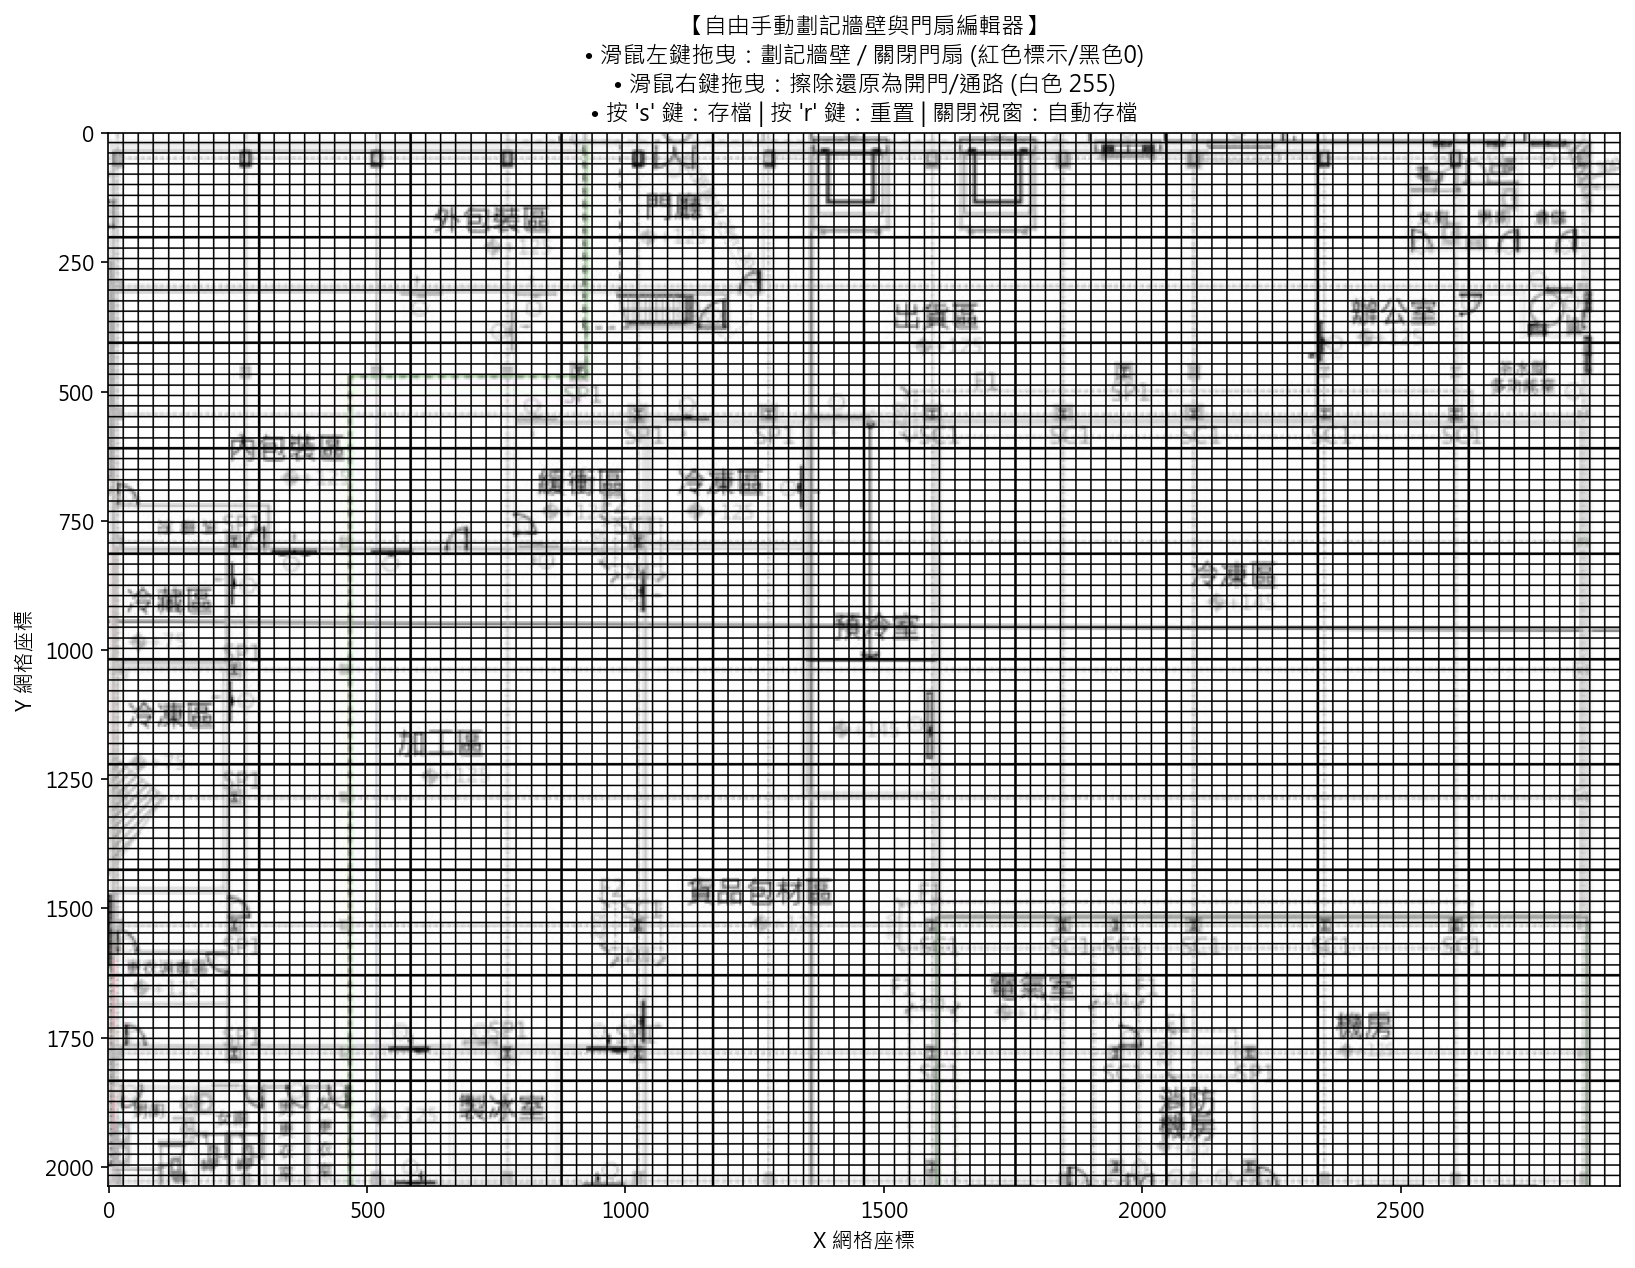

修改後的網格已成功儲存為 'custom_wall_and_doors_matrix.npy'！


In [13]:
import fitz  # PyMuPDF 套件
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. 字型與顯示設定 (避免中文警告)
# ==========================================
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 1. 讀取 PDF 並進行 300 DPI 高畫質渲染 (確保原圖極度清晰)
# ==========================================
pdf_path = "factory.jpg"
grid_rows, grid_cols = 100, 100  # 設定 100x100 網格

doc = fitz.open(pdf_path)
page = doc[0]
zoom = 300 / 72  # 300 DPI 放大渲染
mat = fitz.Matrix(zoom, zoom)
pix = page.get_pixmap(matrix=mat)

high_res_rgb = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
if pix.n == 4:
    high_res_rgb = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGBA2RGB)
    gray = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGB2GRAY)
else:
    gray = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGB2GRAY)

h, w, _ = high_res_rgb.shape

# ==========================================
# 2. 自動提取基礎牆體作為底圖網格
# ==========================================
_, binary_map = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
dilated_map = cv2.erode(binary_map, kernel, iterations=1)
wall_matrix = cv2.resize(dilated_map, (grid_cols, grid_rows), interpolation=cv2.INTER_AREA)
original_wall_matrix = wall_matrix.copy()

# ==========================================
# 3. 繪製高清底圖上的「純黑色粗線網格」
# ==========================================
base_grid_img = high_res_rgb.copy()
row_step = h / grid_rows
col_step = w / grid_cols

black_color = (0, 0, 0)
for i in range(1, grid_cols):
    x = int(i * col_step)
    thick = 4 if i % 10 == 0 else 2
    cv2.line(base_grid_img, (x, 0), (x, h), black_color, thick)

for j in range(1, grid_rows):
    y = int(j * row_step)
    thick = 4 if j % 10 == 0 else 2
    cv2.line(base_grid_img, (0, y), (w, y), black_color, thick)

# ==========================================
# 4. 建立自由手動塗刷編輯器 (自由劃記牆壁與門)
# ==========================================
fig, ax = plt.subplots(figsize=(11, 10), dpi=150)
im = ax.imshow(base_grid_img)

title_text = (
    "【自由手動劃記牆壁與門扇編輯器】\n"
    "• 滑鼠左鍵拖曳：劃記牆壁 / 關閉門扇 (紅色標示/黑色0)\n"
    "• 滑鼠右鍵拖曳：擦除還原為開門/通路 (白色 255)\n"
    "• 按 's' 鍵：存檔 | 按 'r' 鍵：重置 | 關閉視窗：自動存檔"
)
ax.set_title(title_text, fontsize=11)
ax.set_xlabel("X 網格座標")
ax.set_ylabel("Y 網格座標")

drawing = False
brush_size = 1  # 塗刷筆刷大小

def render_display():
    """繪製手動塗刷的區域並疊加顏色提示"""
    overlay = base_grid_img.copy()
    for r in range(grid_rows):
        for c in range(grid_cols):
            # 標示手動塗刷的新牆壁/門扇
            if wall_matrix[r, c] == 0 and original_wall_matrix[r, c] != 0:
                y1, y2 = int(r * row_step), int((r + 1) * row_step)
                x1, x2 = int(c * col_step), int((c + 1) * col_step)
                overlay[y1:y2, x1:x2] = (overlay[y1:y2, x1:x2] * 0.4 + np.array([220, 0, 0]) * 0.6).astype(np.uint8)
    im.set_data(overlay)
    fig.canvas.draw_idle()

def update_point(x, y, value):
    col = int(x / col_step)
    row = int(y / row_step)
    if 0 <= col < grid_cols and 0 <= row < grid_rows:
        r_min, r_max = max(0, row - brush_size), min(grid_rows, row + brush_size + 1)
        c_min, c_max = max(0, col - brush_size), min(grid_cols, col + brush_size + 1)
        wall_matrix[r_min:r_max, c_min:c_max] = value
        render_display()

def on_button_press(event):
    global drawing
    if event.inaxes == ax:
        drawing = True
        val = 0 if event.button == 1 else 255  # 左鍵劃線(0), 右鍵擦除(255)
        update_point(event.xdata, event.ydata, val)

def on_motion(event):
    if drawing and event.inaxes == ax:
        val = 0 if event.button == 1 else 255
        update_point(event.xdata, event.ydata, val)

def on_button_release(event):
    global drawing
    drawing = False

def on_key_press(event):
    global wall_matrix
    if event.key == 'r':  # 重置
        wall_matrix[:] = original_wall_matrix.copy()
        render_display()
        print("已重置圖面！")
    elif event.key == 's':  # 存檔
        save_current_matrix()

def save_current_matrix():
    np.save("custom_wall_and_doors_matrix.npy", wall_matrix)
    cv2.imwrite("custom_wall_and_doors_matrix.png", wall_matrix)
    print("修改後的網格已成功儲存為 'custom_wall_and_doors_matrix.npy'！")

# 綁定事件
fig.canvas.mpl_connect('button_press_event', on_button_press)
fig.canvas.mpl_connect('motion_notify_event', on_motion)
fig.canvas.mpl_connect('button_release_event', on_button_release)
fig.canvas.mpl_connect('key_press_event', on_key_press)

plt.tight_layout()
plt.show()

# 關閉視窗自動存檔
save_current_matrix()

In [20]:
pip install PyQt5


   ---------------------------------------- 0.0/6.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.9 MB ? eta -:--:--
   ---- ----------------------------------- 0.8/6.9 MB 2.4 MB/s eta 0:00:03
   ------- -------------------------------- 1.3/6.9 MB 2.5 MB/s eta 0:00:03
   ---------- ----------------------------- 1.8/6.9 MB 2.4 MB/s eta 0:00:03
   ------------- -------------------------- 2.4/6.9 MB 2.5 MB/s eta 0:00:02
   ---------------- ----------------------- 2.9/6.9 MB 2.5 MB/s eta 0:00:02
   ------------------- -------------------- 3.4/6.9 MB 2.5 MB/s eta 0:00:02
   ---------------------- ----------------- 3.9/6.9 MB 2.5 MB/s eta 0:00:02
   ------------------------- -------------- 4.5/6.9 MB 2.5 MB/s eta 0:00:01
   ----------------------------- ---------- 5.0/6.9 MB 2.5 MB/s eta 0:00:01
   -------------------------------- ------- 5.5/6.9 MB 2.5 MB/s eta 0:00:01
   ----------------------------------- ---- 6.0/6.9 MB 2.5 MB/s eta 0:00:01
   ----------------------

'DOSKEY' ���O�����Υ~���R�O�B�i���檺�{���Χ妸�ɡC
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [21]:
%matplotlib qt
import fitz  # PyMuPDF 套件
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 0. 字型與顯示設定 (避免中文顯示警告)
# ==========================================
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'SimHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 1. 讀取 PDF 並以 300 DPI 渲染 (確保原圖極度清晰)
# ==========================================
pdf_path = "factory.jpg"
grid_rows, grid_cols = 100, 100  # 設定 100x100 網格 (可根據需求修改)

try:
    doc = fitz.open(pdf_path)
    page = doc[0]
    zoom = 300 / 72  # 300 DPI 高畫質放大
    mat = fitz.Matrix(zoom, zoom)
    pix = page.get_pixmap(matrix=mat)

    # 轉換為 RGB 與灰階影像
    high_res_rgb = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    if pix.n == 4:
        high_res_rgb = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGBA2RGB)
    gray = cv2.cvtColor(high_res_rgb, cv2.COLOR_RGB2GRAY)
    h, w, _ = high_res_rgb.shape

    # 自動提取原始 CAD 牆體作為初始二值化網格 (0為牆/不可走，255為路/可走)
    _, binary_map = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    dilated_map = cv2.erode(binary_map, kernel, iterations=1)
    wall_matrix = cv2.resize(dilated_map, (grid_cols, grid_rows), interpolation=cv2.INTER_AREA)
    print("成功載入 PDF 建築結構！")

except Exception as e:
    print(f"無法載入 PDF ({e})，改為建立 {grid_rows}x{grid_cols} 空白網格地圖。")
    h, w = 800, 800
    high_res_rgb = np.full((h, w, 3), 255, dtype=np.uint8)
    wall_matrix = np.full((grid_rows, grid_cols), 255, dtype=np.uint8)

# 備份最原始提取的網格（用於按 R 鍵重置）
original_wall_matrix = wall_matrix.copy()

# ==========================================
# 2. 繪製高清底圖上的純黑色粗線網格
# ==========================================
base_grid_img = high_res_rgb.copy()
row_step = h / grid_rows
col_step = w / grid_cols

black_color = (0, 0, 0)
# 畫縱向黑線
for i in range(1, grid_cols):
    x = int(i * col_step)
    thick = 4 if i % 10 == 0 else 2  # 每 10 格加粗主輔助線
    cv2.line(base_grid_img, (x, 0), (x, h), black_color, thick)

# 畫橫向黑線
for j in range(1, grid_rows):
    y = int(j * row_step)
    thick = 4 if j % 10 == 0 else 2
    cv2.line(base_grid_img, (0, y), (w, y), black_color, thick)

# ==========================================
# 3. 建立【跳出式網格劃記編輯視窗】
# ==========================================
fig, ax = plt.subplots(figsize=(11, 10), dpi=130)
im = ax.imshow(base_grid_img)

title_text = (
    "【動態網格劃記編輯器】\n"
    "• 滑鼠左鍵拖曳：劃記新增【牆壁 / 關閉的門】 (標示為紅色/改為 0 不可走)\n"
    "• 滑鼠右鍵拖曳：擦除還原【通道 / 開啟的門】 (改為 255 可通行)\n"
    "• 鍵盤按 's' 鍵：手動儲存網格 | 鍵盤按 'r' 鍵：重置圖面\n"
    "• 關閉視窗：自動儲存並更新『不能走與可走』的網格陣列！"
)
ax.set_title(title_text, fontsize=11, color='navy', fontweight='bold')
ax.set_xlabel(f"X 網格座標 (0 ~ {grid_cols-1})")
ax.set_ylabel(f"Y 網格座標 (0 ~ {grid_rows-1})")

drawing = False
brush_size = 1  # 塗刷筆刷半徑 (1 表示 3x3 網格區塊，可微調)

def render_display():
    """即時重新渲染：底圖 + 黑色網格 + 手動新增劃記的紅色遮罩"""
    overlay = base_grid_img.copy()
    
    # 找出手動劃記為 0 (牆/關門) 的網格區塊疊加半透明紅色
    for r in range(grid_rows):
        for c in range(grid_cols):
            if wall_matrix[r, c] == 0 and original_wall_matrix[r, c] != 0:
                y1, y2 = int(r * row_step), int((r + 1) * row_step)
                x1, x2 = int(c * col_step), int((c + 1) * col_step)
                overlay[y1:y2, x1:x2] = (overlay[y1:y2, x1:x2] * 0.3 + np.array([230, 30, 30]) * 0.7).astype(np.uint8)
                
    im.set_data(overlay)
    fig.canvas.draw_idle()

def update_point(x, y, value):
    """將滑鼠點擊位置精確對應至網格矩陣中的 (row, col) 並賦值"""
    col = int(x / col_step)
    row = int(y / row_step)
    
    if 0 <= col < grid_cols and 0 <= row < grid_rows:
        r_min, r_max = max(0, row - brush_size), min(grid_rows, row + brush_size + 1)
        c_min, c_max = max(0, col - brush_size), min(grid_cols, col + brush_size + 1)
        
        wall_matrix[r_min:r_max, c_min:c_max] = value
        render_display()

# 滑鼠與鍵盤事件監聽機制
def on_button_press(event):
    global drawing
    if event.inaxes == ax:
        drawing = True
        val = 0 if event.button == 1 else 255  # 左鍵: 0(不可走牆/門), 右鍵: 255(可走通道)
        update_point(event.xdata, event.ydata, val)

def on_motion(event):
    if drawing and event.inaxes == ax:
        val = 0 if event.button == 1 else 255
        update_point(event.xdata, event.ydata, val)

def on_button_release(event):
    global drawing
    drawing = False

def on_key_press(event):
    global wall_matrix
    if event.key == 'r':  # 按 R 鍵重置回到初始狀態
        wall_matrix[:] = original_wall_matrix.copy()
        render_display()
        print("已重置網格為初始狀態！")
    elif event.key == 's':  # 按 S 鍵手動存檔
        save_updated_grid()

def save_updated_grid():
    """自動儲存最新網格數據 (0=不可走，255=可走)"""
    np.save("updated_walkable_grid.npy", wall_matrix)
    cv2.imwrite("updated_walkable_grid.png", wall_matrix)
    
    unwalkable_count = np.sum(wall_matrix == 0)
    walkable_count = np.sum(wall_matrix == 255)
    
    print("\n" + "="*50)
    print("【網格通行狀態已成功自動儲存並更新！】")
    print(f"• 不可通行網格數 (0)   : {unwalkable_count} 個")
    print(f"• 可自由通行網格數 (255): {walkable_count} 個")
    print("• 已儲存 NumPy 矩陣檔 : 'updated_walkable_grid.npy'")
    print("• 已儲存二值化圖像檔   : 'updated_walkable_grid.png'")
    print("="*50 + "\n")

# 綁定事件監聽
fig.canvas.mpl_connect('button_press_event', on_button_press)
fig.canvas.mpl_connect('motion_notify_event', on_motion)
fig.canvas.mpl_connect('button_release_event', on_button_release)
fig.canvas.mpl_connect('key_press_event', on_key_press)

plt.tight_layout()
plt.show()

# 視窗關閉時自動存檔更新
save_updated_grid()

成功載入 PDF 建築結構！

【網格通行狀態已成功自動儲存並更新！】
• 不可通行網格數 (0)   : 4 個
• 可自由通行網格數 (255): 6593 個
• 已儲存 NumPy 矩陣檔 : 'updated_walkable_grid.npy'
• 已儲存二值化圖像檔   : 'updated_walkable_grid.png'

